# Unidad 5 — Proyecto final integrador

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 24-11-2026 (2 horas) · Contenidos 5.1 a 5.5 · **Proyecto final: 40 puntos**

Este notebook es la **plantilla del proyecto**. Funciona de principio a fin con un ejemplo; tu trabajo es cambiar el caso, completar las celdas marcadas con **TU TURNO** y escribir tus interpretaciones.

## Qué se entrega

1. **Este notebook** ejecutado, con tu caso.
2. Un **informe breve**: la ficha ejecutiva de la parte 5 (una página).
3. La **defensa**: una presentación corta de los hallazgos, la incertidumbre y los límites.

## Las cinco partes (contenidos 5.1 a 5.5)

| Parte | Contenido | Qué debes dejar escrito |
|---|---|---|
| 1 | 5.1 Caso, objetivo y métricas | qué decisión apoya el modelo, qué se predice y con qué métrica |
| 2 | 5.2 Modelo avanzado y línea base | la regla simple a superar y al menos un modelo del Módulo 6 |
| 3 | 5.3 Comparación y visualización | tabla en datos no vistos, con intervalo, y un gráfico |
| 4 | 5.4 Presentación ejecutiva | hallazgos, incertidumbre y límites en una página |
| 5 | 5.5 Retroalimentación y siguientes pasos | qué harías con más tiempo o más datos |

## Dos rutas

Elige **una** según tu caso y ejecuta solo esa sección (además de la preparación).

| Ruta | Tipo de problema | Datos de ejemplo | Línea base | Modelos avanzados |
|---|---|---|---|---|
| **A** | **Clasificación** en una tabla (sí o no) | impago de tarjetas | regla de una variable | Naive Bayes, Random Forest, boosting, red neuronal |
| **B** | **Pronóstico** de una serie mensual | exportaciones del Ecuador | promedio móvil de 12 meses | regresión bayesiana, Random Forest, red neuronal |

Puedes usar los datos del módulo, un conjunto del Módulo 3 o del Módulo 5, o datos propios en CSV.

## Qué se valora

La rúbrica oficial está en el instrumento de evaluación del proyecto. En general, pesa más **el razonamiento** que el resultado:

- el problema, el objetivo y la línea base están bien definidos;
- el modelo avanzado se compara con la línea base **en datos que no vio**;
- se informa la incertidumbre (un intervalo) y no solo un número;
- la interpretación económica es correcta y se reconocen las limitaciones;
- **un proyecto en el que el modelo avanzado no supera a la línea base, bien explicado, es un buen proyecto.**

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow

In [2]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /home/claude/m6/datos


In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error

import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')

# 1. Definición del caso (5.1)

**TU TURNO.** Edita esta celda antes de programar. Si no puedes llenar una fila, el problema todavía no está definido.

| Pregunta | Tu respuesta |
|---|---|
| ¿Qué institución o área usaría el modelo? | *(ejemplo: área de riesgo de un banco emisor de tarjetas)* |
| ¿Qué **decisión** apoya? | *(ejemplo: a qué clientes llamar antes del vencimiento)* |
| ¿Cuál es la **variable objetivo**? | *(ejemplo: impago en octubre, sí o no)* |
| ¿Qué información se conoce **antes** de decidir? | *(ejemplo: perfil, atrasos, facturas y pagos hasta septiembre)* |
| ¿Clasificación o pronóstico? | *(Ruta A o Ruta B)* |
| ¿Cuál es la **línea base**? | *(ejemplo: marcar a quien tenga 2 o más meses de atraso)* |
| ¿Con qué **métrica** se compara y por qué? | *(ejemplo: AUC para ordenar, costo para decidir)* |
| ¿Qué error es más caro? | *(ejemplo: no detectar un impago cuesta 5 veces más que una llamada innecesaria)* |

---
# Ruta A — Clasificación en una tabla

## A.1 Configuración

**TU TURNO.** Cambia estos valores por los de tu caso. Con los valores de ejemplo se reproduce el caso del módulo.

In [4]:
# ----------------------------- CONFIGURACIÓN DE LA RUTA A -----------------------------
ARCHIVO = DATA_DIR / 'impago_tarjetas.csv'     # tu archivo CSV (puede ser una ruta propia)
OBJETIVO = 'impago'                            # columna objetivo: 1 = ocurre el suceso, 0 = no ocurre
COLUMNAS_A_QUITAR = ['id']                     # identificadores y columnas que no se conocen antes de decidir

# Línea base: UNA columna y un umbral. Se marca como positivo si la columna supera el umbral.
COLUMNA_REGLA, UMBRAL_REGLA = 'atraso_sep', 2

# Costos para decidir (en las unidades que quieras): actuar sobre un caso y dejar pasar un positivo
COSTO_ACCION, COSTO_OMISION = 1, 5
# ---------------------------------------------------------------------------------------

datos = pd.read_csv(ARCHIVO)
X = datos.drop(columns=COLUMNAS_A_QUITAR + [OBJETIVO])
y = datos[OBJETIVO]

# Si tu tabla tiene columnas de texto, conviértelas en números (una columna por categoría)
X = pd.get_dummies(X, drop_first=True).astype(float)

print('Filas:', len(X), '· columnas:', X.shape[1], '· tasa base del objetivo:', round(y.mean(), 3))
X.head(3)

Filas: 30000 · columnas: 23 · tasa base del objetivo: 0.221


,limite_credito,sexo,educacion,estado_civil,edad,atraso_sep,atraso_ago,atraso_jul,atraso_jun,atraso_may,...,factura_jul,factura_jun,factura_may,factura_abr,pago_sep,pago_ago,pago_jul,pago_jun,pago_may,pago_abr
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,...,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,...,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,...,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0


## A.2 Partición: Train, Validation y Test

60 % para entrenar, 20 % para elegir, 20 % que no se toca hasta el final. Si tus filas tienen fecha (por ejemplo, créditos por mes), **parte por fecha** y no al azar.

In [5]:
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)
print('Train:', len(X_train), '· Validation:', len(X_val), '· Test:', len(X_test))

Train: 18000 · Validation: 6000 · Test: 6000


## A.3 Línea base y modelos (5.2)

La línea base es la regla de una variable. Los modelos avanzados son los del módulo. **TU TURNO:** deja al menos uno, quita los que no uses o cambia sus hiperparámetros.

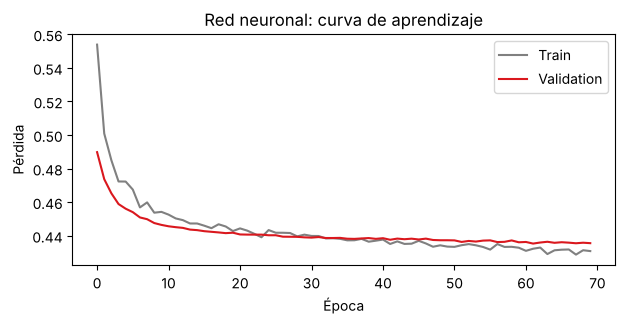

In [6]:
def crear_red(entradas, capas=(32, 16), dropout=0.3):
    """Perceptrón multicapa de la Unidad 3 para clasificación de sí o no."""
    keras.utils.set_random_seed(42)
    red = keras.Sequential([keras.Input(shape=(entradas,))])
    for neuronas in capas:
        red.add(layers.Dense(neuronas, activation='relu'))
        red.add(layers.Dropout(dropout))
    red.add(layers.Dense(1, activation='sigmoid'))
    red.compile(optimizer=keras.optimizers.Adam(0.001), loss='binary_crossentropy')
    return red

modelos = {
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
}

prob_val, prob_test = {}, {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    prob_val[nombre] = modelo.predict_proba(X_val)[:, 1]
    prob_test[nombre] = modelo.predict_proba(X_test)[:, 1]      # se calcula ahora, se mira al final

# Red neuronal: entradas normalizadas con Train y parada temprana vigilando Validation
escalador = StandardScaler().fit(X_train)
red = crear_red(X_train.shape[1])
parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
historia = red.fit(escalador.transform(X_train), y_train, validation_data=(escalador.transform(X_val), y_val),
                   epochs=100, batch_size=128, verbose=0, callbacks=[parada])
prob_val['Red neuronal'] = red.predict(escalador.transform(X_val), verbose=0).ravel()
prob_test['Red neuronal'] = red.predict(escalador.transform(X_test), verbose=0).ravel()

# Curva de aprendizaje de la red (Unidad 3): ¿hay sobreajuste?
pd.DataFrame(historia.history).rename(columns={'loss': 'Train', 'val_loss': 'Validation'}).plot(figsize=(7, 3), color=['gray', '#DA181E'], title='Red neuronal: curva de aprendizaje')
plt.xlabel('Época'); plt.ylabel('Pérdida'); plt.show()

## A.4 Elegir con Validation

Comparamos en Validation y **elegimos aquí**. La línea base entra en la misma tabla.

In [7]:
umbral_costo = COSTO_ACCION / COSTO_OMISION          # regla de la Unidad 2: actuar si p > costo de actuar / costo de omitir

def costo(y_real, actuar):
    """Costo total: cada acción cuesta COSTO_ACCION; cada positivo sin acción cuesta COSTO_OMISION."""
    return actuar.sum() * COSTO_ACCION + ((~actuar) & (y_real.values == 1)).sum() * COSTO_OMISION

def tabla_resultados(X_parte, y_parte, probabilidades):
    regla = (X_parte[COLUMNA_REGLA] >= UMBRAL_REGLA).values
    filas = [{'Modelo': 'Línea base (regla)', 'AUC': roc_auc_score(y_parte, X_parte[COLUMNA_REGLA]), 'Brier': np.nan,
              'Costo': costo(y_parte, regla), 'Positivos alcanzados': regla[y_parte.values == 1].mean()}]
    for nombre, prob in probabilidades.items():
        actuar = prob > umbral_costo
        filas.append({'Modelo': nombre, 'AUC': roc_auc_score(y_parte, prob), 'Brier': brier_score_loss(y_parte, prob),
                      'Costo': costo(y_parte, actuar), 'Positivos alcanzados': actuar[y_parte.values == 1].mean()})
    return pd.DataFrame(filas).set_index('Modelo').sort_values('AUC', ascending=False)

print('Umbral que sale de los costos:', round(umbral_costo, 2))
tabla_val = tabla_resultados(X_val, y_val, prob_val)
tabla_val.round(3)

Umbral que sale de los costos: 0.2


,AUC,Brier,Costo,Positivos alcanzados
Modelo,,,,
Random Forest,0.783,0.135,4277,0.690
Boosting,0.781,0.135,4278,0.646
Red neuronal,0.777,0.137,4240,0.680
Naive Bayes,0.734,0.216,5084,0.812
Regresión logística,0.724,0.145,4753,0.702
Línea base (regla),0.683,NaN,5164,0.313


In [8]:
# TU TURNO: escribe el nombre del modelo que eliges CON LA TABLA DE VALIDATION (no con el Test).
MODELO_ELEGIDO = tabla_val.drop(index='Línea base (regla)')['AUC'].idxmax()     # por defecto, el de mayor AUC
print('Modelo elegido con Validation:', MODELO_ELEGIDO)

Modelo elegido con Validation: Random Forest


## A.5 Comparación final en el Test, con incertidumbre (5.3)

El Test se abre **una vez**. El intervalo del AUC se calcula por remuestreo (Unidad 4).

In [9]:
tabla_test = tabla_resultados(X_test, y_test, prob_test)

# Intervalo del 95 % del AUC por remuestreo: 500 "otros Test posibles"
generador = np.random.default_rng(42)
y_real = y_test.values
sorteos = [generador.integers(0, len(y_real), len(y_real)) for _ in range(500)]
for nombre, prob in prob_test.items():
    aucs = [roc_auc_score(y_real[filas], prob[filas]) for filas in sorteos]
    tabla_test.loc[nombre, 'AUC IC bajo'], tabla_test.loc[nombre, 'AUC IC alto'] = np.quantile(aucs, [0.025, 0.975])

# ¿La ventaja del modelo elegido sobre la regresión logística es real?
diferencia = [roc_auc_score(y_real[f], prob_test[MODELO_ELEGIDO][f]) - roc_auc_score(y_real[f], prob_test['Regresión logística'][f]) for f in sorteos]
print(f'{MODELO_ELEGIDO} - Regresión logística: {np.mean(diferencia):+.3f} · IC 95 %: [{np.quantile(diferencia, 0.025):+.3f}, {np.quantile(diferencia, 0.975):+.3f}]')
tabla_test.round(3)

Random Forest - Regresión logística: +0.060 · IC 95 %: [+0.046, +0.075]


,AUC,Brier,Costo,Positivos alcanzados,AUC IC bajo,AUC IC alto
Modelo,,,,,,
Boosting,0.778,0.136,4265,0.652,0.763,0.794
Red neuronal,0.775,0.137,4384,0.664,0.761,0.791
Random Forest,0.768,0.137,4386,0.672,0.754,0.785
Naive Bayes,0.723,0.223,5105,0.814,0.707,0.740
Regresión logística,0.709,0.146,4965,0.677,0.691,0.727
Línea base (regla),0.676,NaN,5076,0.331,NaN,NaN


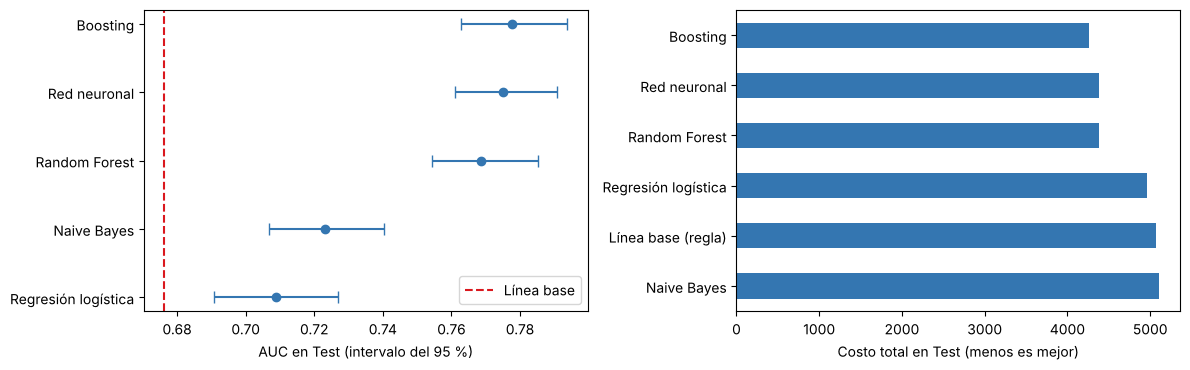

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))

# Izquierda: AUC con su intervalo
orden = tabla_test.dropna(subset=['AUC IC bajo']).sort_values('AUC')
ejes[0].errorbar(orden['AUC'], orden.index, xerr=[orden['AUC'] - orden['AUC IC bajo'], orden['AUC IC alto'] - orden['AUC']], fmt='o', color='#3476B1', capsize=4)
ejes[0].axvline(tabla_test.loc['Línea base (regla)', 'AUC'], color='#DA181E', linestyle='--', label='Línea base')
ejes[0].set_xlabel('AUC en Test (intervalo del 95 %)'); ejes[0].legend()

# Derecha: costo total
tabla_test['Costo'].sort_values(ascending=False).plot(kind='barh', ax=ejes[1], color='#3476B1')
ejes[1].set_xlabel('Costo total en Test (menos es mejor)'); ejes[1].set_ylabel('')
plt.tight_layout(); plt.show()

**TU TURNO: interpretación (edita esta celda).**

1. ¿El modelo elegido supera a la línea base? ¿Por cuánto, en AUC y en costo?
2. ¿La diferencia con los otros modelos es mayor que el margen de error (los intervalos se solapan)?
3. ¿Las probabilidades son creíbles (Brier)? ¿Algún modelo ordena bien pero decide mal?
4. ¿Qué significa el resultado para la institución, en una frase sin tecnicismos?

---
# Ruta B — Pronóstico de una serie mensual

## B.1 Configuración

**TU TURNO.** Elige la serie y las fechas. Con los valores de ejemplo se pronostica la **variación mensual de las exportaciones** del Ecuador (el reto del Día 4 del Módulo 5).

Columnas disponibles en `series_economicas.csv`: `ipc_var_mensual`, `exportaciones_fob_musd`, `exportaciones_petroleras_musd`, `importaciones_fob_musd`, `balanza_comercial_musd`, `riesgo_pais_pb`, `precio_crudo_oriente_usd`, `precio_wti_usd`, `liquidez_m2_musd`, `reservas_internacionales_musd`, `salario_real_indice`, `tasa_activa_ref_pct`, `tasa_pasiva_ref_pct`.

Train: 203 meses · Validation: 24 · Test: 20 (2025-01 a 2026-08)


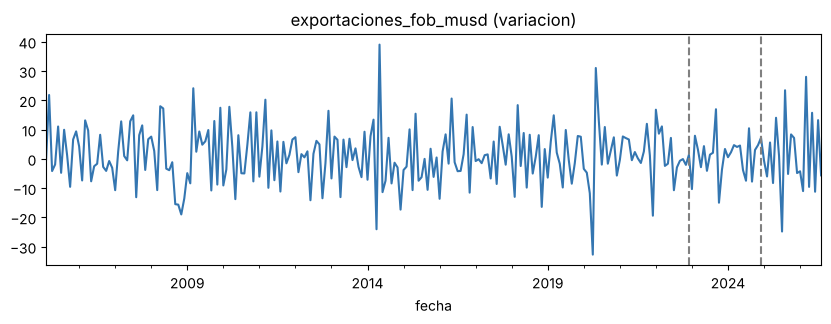

In [11]:
# ----------------------------- CONFIGURACIÓN DE LA RUTA B -----------------------------
COLUMNA = 'exportaciones_fob_musd'    # serie a pronosticar
TRANSFORMACION = 'variacion'          # 'variacion' = % mensual (para series con tendencia) · 'nivel' = tal como viene (para series que oscilan, como la inflación)
INICIO = '2005'                       # desde cuándo usar la serie
FIN_TRAIN = '2022-12'                 # hasta aquí se entrena
FIN_VALIDATION = '2024-12'            # hasta aquí se valida; lo que sigue es el Test
# ---------------------------------------------------------------------------------------

series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
serie = series[COLUMNA].loc[INICIO:].dropna()
if TRANSFORMACION == 'variacion':
    serie = (serie.pct_change() * 100).dropna()          # el velocímetro, no el odómetro (Módulo 5)

# Tabla de aprendizaje supervisado (Módulo 5, Día 4): primero shift, después rolling
tabla = pd.DataFrame({'objetivo': serie})
for k in [1, 2, 3, 6, 12]:
    tabla[f'rezago_{k}'] = serie.shift(k)
tabla['media_3'] = serie.shift(1).rolling(3).mean()
tabla['media_12'] = serie.shift(1).rolling(12).mean()      # esta columna ES la línea base (PM12)
tabla['mes'] = tabla.index.month
tabla = tabla.dropna()
columnas = tabla.columns.drop('objetivo')

# Partición POR FECHA, nunca al azar
train = tabla.loc[:FIN_TRAIN]
val = tabla.loc[pd.Timestamp(FIN_TRAIN) + pd.offsets.MonthBegin(1):FIN_VALIDATION]
test = tabla.loc[pd.Timestamp(FIN_VALIDATION) + pd.offsets.MonthBegin(1):]
print('Train:', len(train), 'meses · Validation:', len(val), '· Test:', len(test), f'({test.index.min():%Y-%m} a {test.index.max():%Y-%m})')

serie.plot(figsize=(10, 3), color='#3476B1', title=f'{COLUMNA} ({TRANSFORMACION})')
plt.axvline(pd.Timestamp(FIN_TRAIN), color='gray', linestyle='--'); plt.axvline(pd.Timestamp(FIN_VALIDATION), color='gray', linestyle='--')
plt.show()

## B.2 Línea base y modelos (5.2)

- **Línea base:** promedio móvil de 12 meses (y el ingenuo, como referencia).
- **Regresión bayesiana:** pronóstico con su incertidumbre (Unidad 2).
- **Random Forest:** el modelo del Módulo 5.
- **Red neuronal:** salida lineal y pérdida MAE (Unidad 4).

Todos pronostican **a un mes**. Para elegir se entrenan con Train y se miden en Validation.

In [12]:
def ajustar_modelos(entrena):
    """Entrena los tres modelos con los meses indicados y devuelve una función que pronostica."""
    escala = StandardScaler().fit(entrena[columnas])
    bayesiana = BayesianRidge().fit(escala.transform(entrena[columnas]), entrena['objetivo'])
    bosque = RandomForestRegressor(n_estimators=200, max_depth=5, max_features=0.5, random_state=42).fit(entrena[columnas], entrena['objetivo'])

    keras.utils.set_random_seed(42)
    red = keras.Sequential([keras.Input(shape=(len(columnas),)), layers.Dense(8, activation='relu'), layers.Dense(1)])
    red.compile(optimizer=keras.optimizers.Adam(0.01), loss='mae')
    red.fit(escala.transform(entrena[columnas]), entrena['objetivo'], epochs=150, batch_size=32, verbose=0)

    def pronosticar(parte):
        media, desviacion = bayesiana.predict(escala.transform(parte[columnas]), return_std=True)
        pronosticos = pd.DataFrame({
            'Línea base: promedio móvil 12': parte['media_12'],
            'Ingenuo (mes anterior)': parte['rezago_1'],
            'Regresión bayesiana': media,
            'Random Forest': bosque.predict(parte[columnas]),
            'Red neuronal': red.predict(escala.transform(parte[columnas]), verbose=0).ravel(),
        }, index=parte.index)
        return pronosticos, desviacion
    return pronosticar

# Elegir: entrenar con Train, medir en Validation
pronosticos_val, _ = ajustar_modelos(train)(val)
mae_val = pronosticos_val.apply(lambda columna: mean_absolute_error(val['objetivo'], columna)).sort_values()
mae_val.round(3).to_frame('MAE en Validation')

,MAE en Validation
Regresión bayesiana,5.146
Random Forest,5.444
Línea base: promedio móvil 12,5.771
Red neuronal,7.841
Ingenuo (mes anterior),8.277


In [13]:
# TU TURNO: escribe el nombre del modelo avanzado que eliges CON VALIDATION.
avanzados = ['Regresión bayesiana', 'Random Forest', 'Red neuronal']
MODELO_ELEGIDO_B = mae_val[avanzados].idxmin()          # por defecto, el de menor MAE en Validation
print('Modelo avanzado elegido con Validation:', MODELO_ELEGIDO_B)

Modelo avanzado elegido con Validation: Regresión bayesiana


## B.3 Comparación final en el Test, con incertidumbre (5.3)

Reentrenamos con Train + Validation y pronosticamos el Test, una sola vez.

La incertidumbre se informa de dos formas: el **intervalo de la regresión bayesiana** para cada mes y un **intervalo por remuestreo** para la diferencia de error entre el modelo elegido y la línea base.

In [14]:
pronosticos_test, desviacion_test = ajustar_modelos(pd.concat([train, val]))(test)
real = test['objetivo']

errores = pronosticos_test.sub(real, axis=0).abs()          # error absoluto de cada modelo en cada mes
tabla_b = pd.DataFrame({'MAE en Test': errores.mean(), 'MAE en Validation': mae_val}).sort_values('MAE en Test')

# ¿El modelo elegido es mejor que la línea base, o es suerte? Remuestreo de los meses del Test
generador = np.random.default_rng(42)
diferencia = errores[MODELO_ELEGIDO_B] - errores['Línea base: promedio móvil 12']       # negativo = gana el modelo elegido
sorteos = [diferencia.values[generador.integers(0, len(diferencia), len(diferencia))].mean() for _ in range(2000)]
print(f'{MODELO_ELEGIDO_B} menos línea base: {diferencia.mean():+.3f} · IC 95 %: [{np.quantile(sorteos, 0.025):+.3f}, {np.quantile(sorteos, 0.975):+.3f}]  (negativo = el modelo elegido se equivoca menos)')

# ¿Cuántos meses del Test cayeron dentro del intervalo del 95 % de la regresión bayesiana?
bajo = pronosticos_test['Regresión bayesiana'] - 1.96 * desviacion_test
alto = pronosticos_test['Regresión bayesiana'] + 1.96 * desviacion_test
print(f'Meses dentro del intervalo del 95 % de la regresión bayesiana: {((real >= bajo) & (real <= alto)).mean():.0%}')
tabla_b.round(3)

Regresión bayesiana menos línea base: -1.562 · IC 95 %: [-2.934, -0.243]  (negativo = el modelo elegido se equivoca menos)
Meses dentro del intervalo del 95 % de la regresión bayesiana: 90%


,MAE en Test,MAE en Validation
Red neuronal,8.010,7.841
Random Forest,8.885,5.444
Regresión bayesiana,9.361,5.146
Línea base: promedio móvil 12,10.922,5.771
Ingenuo (mes anterior),19.136,8.277


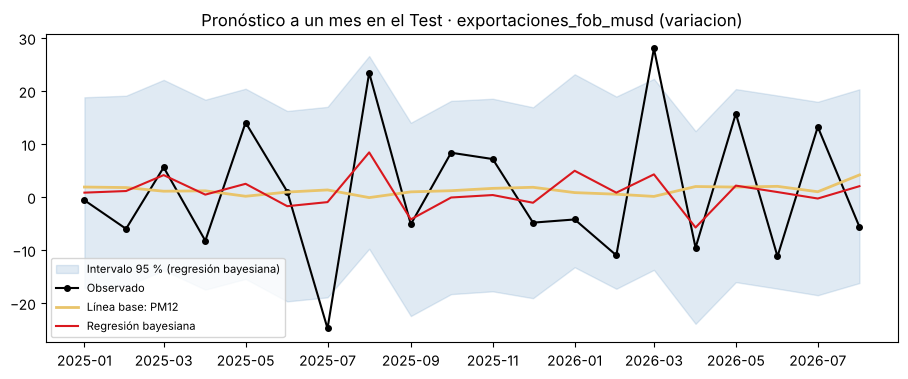

In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(test.index, bajo, alto, color='#3476B1', alpha=0.15, label='Intervalo 95 % (regresión bayesiana)')
ax.plot(real, 'ko-', markersize=4, label='Observado')
ax.plot(pronosticos_test['Línea base: promedio móvil 12'], color='#E9C46A', linewidth=2, label='Línea base: PM12')
ax.plot(pronosticos_test[MODELO_ELEGIDO_B], color='#DA181E', label=MODELO_ELEGIDO_B)
ax.set_title(f'Pronóstico a un mes en el Test · {COLUMNA} ({TRANSFORMACION})'); ax.legend(fontsize=8)
plt.show()

**TU TURNO: interpretación (edita esta celda).**

1. ¿El modelo elegido supera a la línea base en el Test? ¿El intervalo de la diferencia incluye el cero?
2. ¿El orden de los modelos en Validation se mantuvo en el Test?
3. ¿El intervalo de la regresión bayesiana contuvo a los meses observados? ¿Es útil o es demasiado ancho?
4. ¿Qué explica económicamente los meses con mayor error?

---
# 4. Presentación ejecutiva (5.4)

**TU TURNO.** Completa la ficha con tus resultados. Es lo que presentarás en la defensa: una página, sin código y sin jerga.

```
FICHA EJECUTIVA · (título de tu caso)
====================================================
1. PROBLEMA
   ¿Qué decisión se quiere apoyar y quién la toma?

2. QUÉ SE HIZO
   Datos (fuente, periodo, número de filas), variable objetivo,
   línea base y modelo avanzado.

3. RESULTADO
   El número principal, comparado con la línea base, en datos no vistos.
   Traducido a algo que le importe a quien decide (costo, casos alcanzados, error en puntos).

4. CUÁNTO CONFIAR
   El intervalo. ¿La mejora es mayor que el margen de error?

5. LIMITACIONES
   Al menos tres: representatividad de los datos, estabilidad en el tiempo,
   asociación frente a causa, costos supuestos, equidad, mantenimiento.

6. RECOMENDACIÓN
   ¿Usar el modelo, usar la línea base, o reunir más datos? ¿Por qué?
```

## Guía para la defensa

| Minuto | Contenido |
|---|---|
| 1 | El problema y la decisión |
| 2 | Los datos, el objetivo y la línea base |
| 3 | El modelo avanzado y **un** gráfico de comparación |
| 4 | Cuánto confiar: el intervalo y las limitaciones |
| 5 | La recomendación |

Tres preguntas que conviene tener preparadas:

1. **¿Por qué esa línea base?**
2. **Si el modelo se equivoca, ¿qué error es más caro y cómo lo tuviste en cuenta?**
3. **¿Qué tendría que pasar para que dejaras de confiar en este modelo?**

# 5. Retroalimentación y siguientes pasos (5.5)

**TU TURNO (edita esta celda).**

- ¿Qué harías con el doble de datos?
- ¿Qué variable que no tienes crees que mejoraría más el modelo?
- ¿Cada cuánto habría que reentrenarlo y quién debería vigilarlo?
- ¿Qué aprendiste de la retroalimentación de tus compañeros?

## Checklist de entrega

- [ ] Llené la tabla de definición del caso (parte 1).
- [ ] Hay una línea base y al menos un modelo avanzado del Módulo 6.
- [ ] Elegí con Validation y abrí el Test una sola vez.
- [ ] La tabla de comparación tiene un intervalo, no solo un número.
- [ ] Hay un gráfico que se entiende sin explicación.
- [ ] Escribí la interpretación con mis palabras.
- [ ] La ficha ejecutiva cabe en una página e incluye limitaciones.
- [ ] El notebook se ejecuta de principio a fin (Kernel → Restart & Run All).

## Lo que nos llevamos del módulo

| Unidad | Idea central |
|---|---|
| 1. No paramétricos | Los conjuntos de árboles son difíciles de superar en tablas; siempre se compara con una regla simple |
| 2. Bayes | Una evidencia se lee con la tasa base; una probabilidad creíble permite decidir con costos |
| 3. Deep Learning | Una red es una cadena de sumas ponderadas que aprende por pasos pequeños; más grande no es mejor |
| 4. Aplicaciones | Un modelo sirve si mejora una decisión y dice cuánto confiar en él |
| 5. Proyecto | Lo complejo tiene que demostrar que le gana a lo simple, en datos que no vio |